In [ ]:
!pip install pandas numpy matplotlib seaborn

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving books_data (1).csv to books_data (1).csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("books_data (1).csv")

# Display first 5 rows
print(df.head())

                               Book Name    Price Rating
0                   A Light in the Attic  Â£51.77  Three
1                     Tipping the Velvet  Â£53.74    One
2                             Soumission  Â£50.10    One
3                          Sharp Objects  Â£47.82   Four
4  Sapiens: A Brief History of Humankind  Â£54.23   Five


In [ ]:
# Dataset shape
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns)

# Data types
print("\nData Types:")
print(df.dtypes)

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (20, 3)

Column Names:
Index(['Book Name', 'Price', 'Rating'], dtype='object')

Data Types:
Book Name    object
Price        object
Rating       object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Book Name  20 non-null     object
 1   Price      20 non-null     object
 2   Rating     20 non-null     object
dtypes: object(3)
memory usage: 612.0+ bytes

Statistical Summary:
                   Book Name    Price Rating
count                     20       20     20
unique                    20       20      5
top     A Light in the Attic  Â£51.77    One
freq                       1        1      6


In [ ]:
# Missing values
print("Missing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Check unique values
print("\nUnique Values:")
print(df.nunique())

Missing Values:
Book Name    0
Price        0
Rating       0
dtype: int64

Duplicate Rows:
0

Unique Values:
Book Name    20
Price        20
Rating        5
dtype: int64


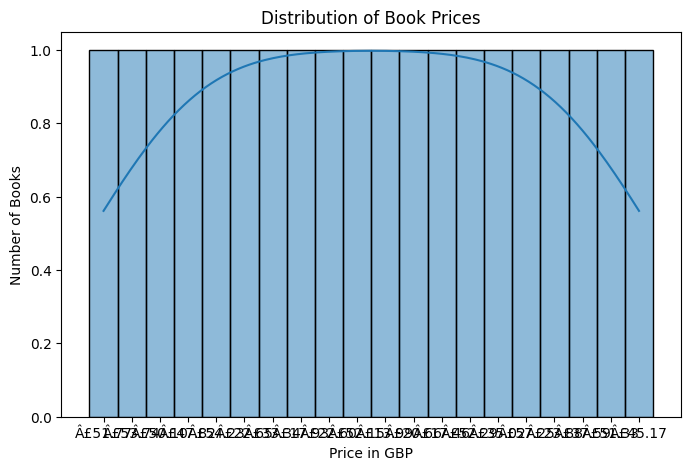

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["Price"],
    bins=20,
    kde=True
)

plt.title("Distribution of Book Prices")
plt.xlabel("Price in GBP")
plt.ylabel("Number of Books")

plt.show()

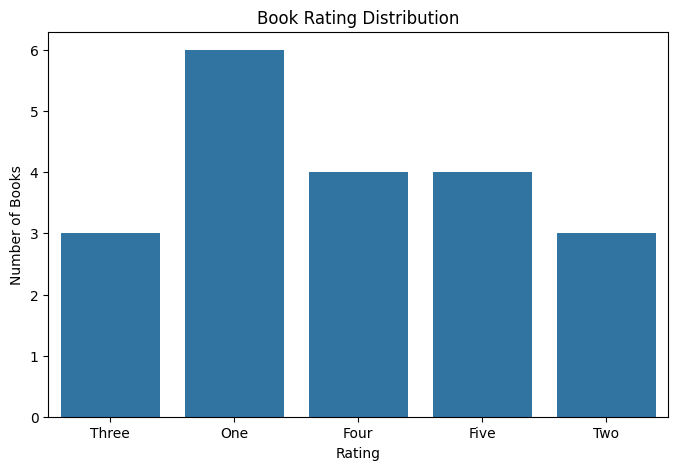

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Rating"
)

plt.title("Book Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Books")

plt.show()

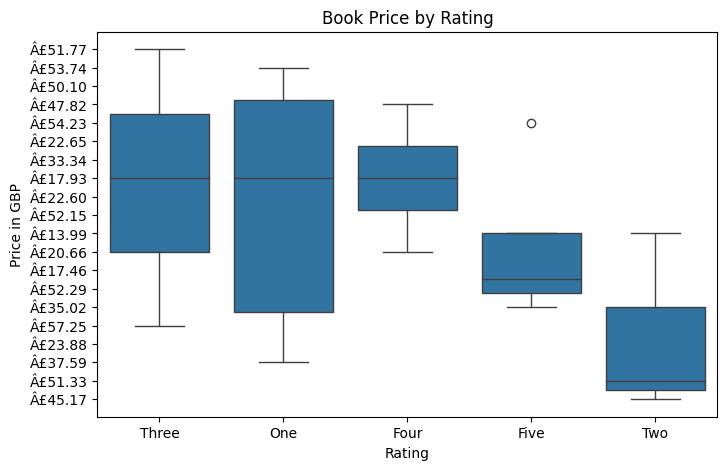

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Rating",
    y="Price"
)

plt.title("Book Price by Rating")
plt.xlabel("Rating")
plt.ylabel("Price in GBP")

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving books_data (1).csv to books_data (1).csv


In [ ]:
df = pd.read_csv("books_data (1).csv")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
                               Book Name    Price Rating
0                   A Light in the Attic  Â£51.77  Three
1                     Tipping the Velvet  Â£53.74    One
2                             Soumission  Â£50.10    One
3                          Sharp Objects  Â£47.82   Four
4  Sapiens: A Brief History of Humankind  Â£54.23   Five


In [ ]:
print(df.columns.tolist())
print(df.dtypes)

['Book Name', 'Price', 'Rating']
Book Name    object
Price        object
Rating       object
dtype: object


In [ ]:
df["Price_GBP"] = pd.to_numeric(
    df["Price_GBP"], errors="coerce"
)

print("Average Price:", df["Price_GBP"].mean())
print("Highest Price:", df["Price_GBP"].max())
print("Lowest Price:", df["Price_GBP"].min())

KeyError: 'Price_GBP'

In [ ]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Book Name', 'Price', 'Rating']


In [ ]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Book Name', 'Price', 'Rating']


In [ ]:
for col in df.columns:
    print(col, ":", df[col].head(3).tolist())

Book Name : ['A Light in the Attic', 'Tipping the Velvet', 'Soumission']
Price : ['Â£51.77', 'Â£53.74', 'Â£50.10']
Rating : ['Three', 'One', 'One']


In [ ]:
# Clean price column

df["Price"] = (
    df["Price"]
    .astype(str)
    .str.replace("Â", "", regex=False)
    .str.replace("£", "", regex=False)
)

# Convert price to numeric
df["Price"] = pd.to_numeric(
    df["Price"], errors="coerce"
)

# Convert rating words into numbers
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df["Rating"] = df["Rating"].map(rating_map)

print(df.head())
print(df.dtypes)

                               Book Name  Price  Rating
0                   A Light in the Attic  51.77       3
1                     Tipping the Velvet  53.74       1
2                             Soumission  50.10       1
3                          Sharp Objects  47.82       4
4  Sapiens: A Brief History of Humankind  54.23       5
Book Name     object
Price        float64
Rating         int64
dtype: object


In [ ]:
print("Average Book Price:")
print(df["Price"].mean())

print("\nHighest Book Price:")
print(df["Price"].max())

print("\nLowest Book Price:")
print(df["Price"].min())

Average Book Price:
38.048500000000004

Highest Book Price:
57.25

Lowest Book Price:
13.99


In [ ]:
print("Rating Counts:")
print(df["Rating"].value_counts().sort_index())

print("\nAverage Price by Rating:")
print(df.groupby("Rating")["Price"].mean())

Rating Counts:
Rating
1    6
2    3
3    3
4    4
5    4
Name: count, dtype: int64

Average Price by Rating:
Rating
1    40.018333
2    36.830000
3    42.316667
4    31.105000
5    39.750000
Name: Price, dtype: float64


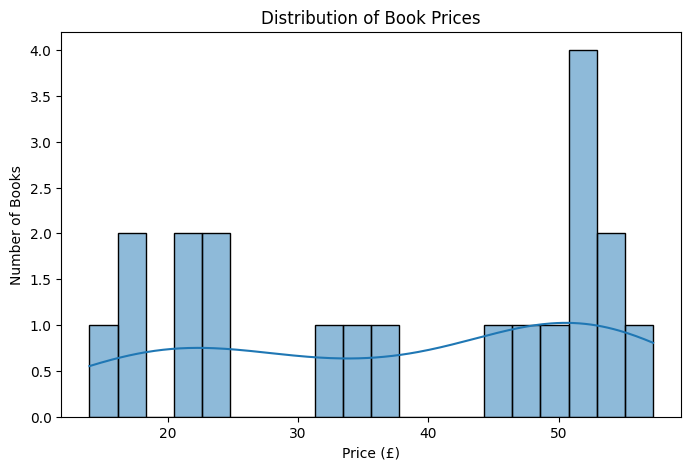

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.histplot(df["Price"], bins=20, kde=True)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")

plt.show()

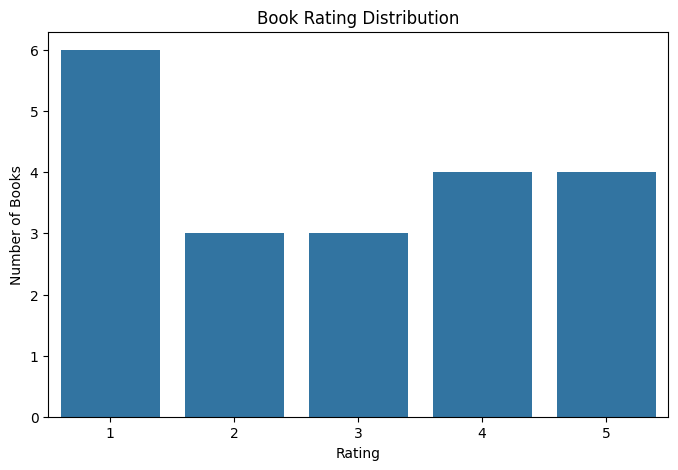

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Rating")

plt.title("Book Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Books")

plt.show()

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nDataset Shape:")
print(df.shape)

Missing Values:
Book Name    0
Price        0
Rating       0
dtype: int64

Duplicate Records:
0

Dataset Shape:
(20, 3)


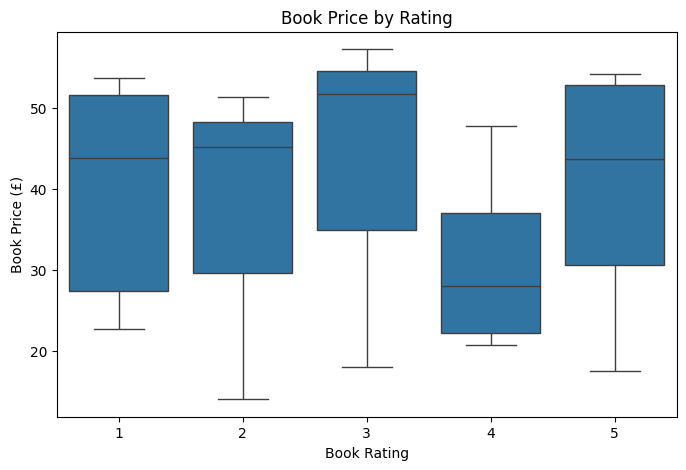

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Rating",
    y="Price"
)

plt.title("Book Price by Rating")
plt.xlabel("Book Rating")
plt.ylabel("Book Price (£)")

plt.show()

In [ ]:
correlation = df["Rating"].corr(df["Price"])

print("Correlation between Rating and Price:")
print(correlation)

Correlation between Rating and Price:
-0.07585689715186737


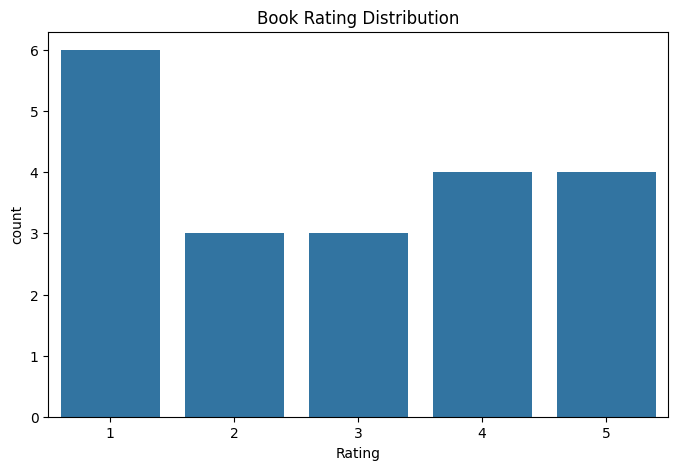

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Rating")

plt.title("Book Rating Distribution")

plt.savefig(
    "rating_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from scipy.stats import pearsonr

r, p = pearsonr(df["Rating"], df["Price"])

print("Correlation:", r)
print("P-value:", p)

if p < 0.05:
    print("Reject Null Hypothesis")
else:
    print("Fail to Reject Null Hypothesis")

Correlation: -0.07585689715186739
P-value: 0.7505934038042006
Fail to Reject Null Hypothesis


In [ ]:
df.to_csv("books_eda_dataset.csv", index=False)

print("EDA Dataset Saved Successfully!")

EDA Dataset Saved Successfully!
